# 01. Exploratory Data Analysis — Delhi Air Quality Daily Series

This notebook explores the complete daily calendar series (`data/processed/clean_daily.csv`, 3,195 days from 2018-01-01 to 2026-09-30) constructed from the CPCB monitoring network in Delhi.

**Project Rules applied:**
- Work on the complete daily calendar (4 missing-AQI days remain NaN; no imputation).
- CPCB-style NAQI calculation (breakpoints pending verification by the project owner against the official CPCB report).
- Every interpretation describes only what the data shows (Rule 7: never invent facts or unverified causes).
- All figures are saved to `outputs/eda/`.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import acf, pacf

# Configure plotting
os.environ["MPLCONFIGDIR"] = "C:/Users/Noman/AppData/Local/Temp/mpl"
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

REPO_ROOT = Path("..").resolve()
EDA_DIR = REPO_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Load clean daily table
daily_csv = REPO_ROOT / "data" / "processed" / "clean_daily.csv"
df = pd.read_csv(daily_csv)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")

print(f"Loaded {len(df)} calendar days ({df['date'].min().date()} to {df['date'].max().date()}).")
print(f"Valid AQI days: {df['aqi'].notna().sum()} | Missing AQI days: {df['aqi'].isna().sum()}")


## 1. Daily AQI Over Time with 30-Day Rolling Mean

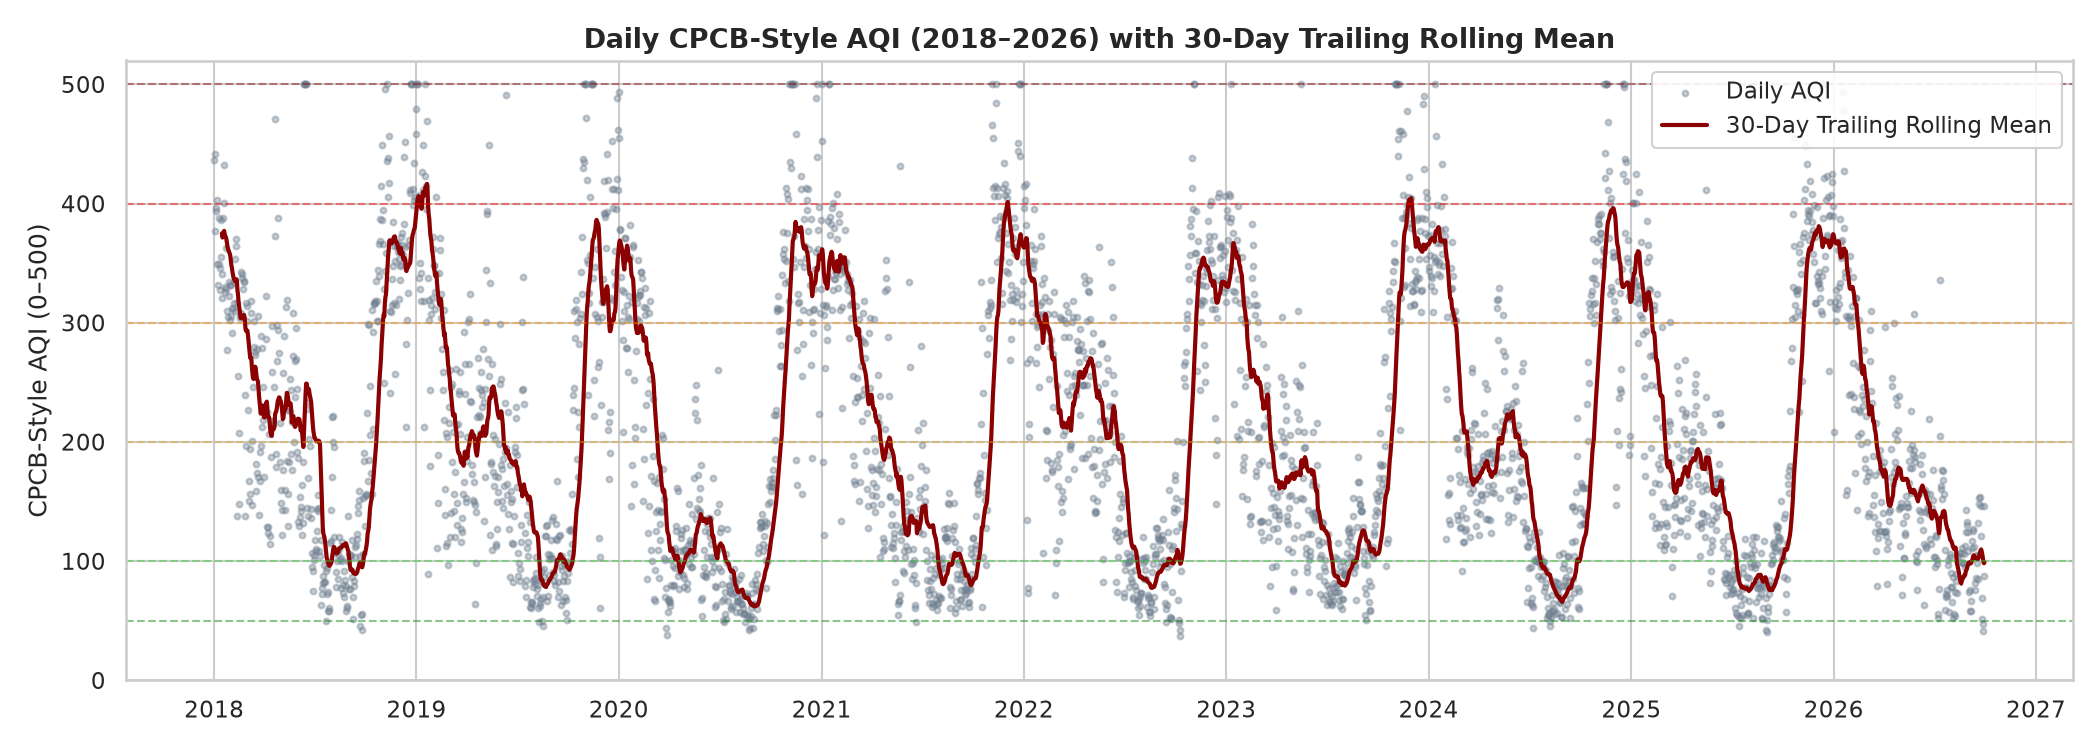

In [2]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(df["date"], df["aqi"], color="slategray", s=8, alpha=0.4, label="Daily AQI")
df["rolling_30d"] = df["aqi"].rolling(window=30, min_periods=15).mean()
ax.plot(df["date"], df["rolling_30d"], color="darkred", lw=2, label="30-Day Trailing Rolling Mean")

bands = [
    (50, "Good (50)", "green"),
    (100, "Satisfactory (100)", "limegreen"),
    (200, "Moderate (200)", "goldenrod"),
    (300, "Poor (300)", "darkorange"),
    (400, "Very Poor (400)", "red"),
    (500, "Severe (500)", "darkred"),
]
for y_val, lbl, c in bands:
    ax.axhline(y_val, color=c, linestyle="--", alpha=0.45, lw=1)

ax.set_ylim(0, 520)
ax.set_ylabel("CPCB-Style AQI (0–500)")
ax.set_title("Daily CPCB-Style AQI (2018–2026) with 30-Day Trailing Rolling Mean", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", framealpha=0.9)
plt.tight_layout()
plt.savefig(EDA_DIR / "01_daily_aqi_over_time.png", dpi=150)
plt.show()


Daily AQI exhibits a recurring annual cycle across all nine years, with peak values consistently concentrating between October and February and minimum values occurring between July and September. The 30-day trailing rolling mean demonstrates that sustained periods in the Poor to Very Poor categories persist for multiple months each winter before dropping back to Moderate levels during the summer and monsoon periods.

## 2. Average AQI by Month and Monthly Heatmap

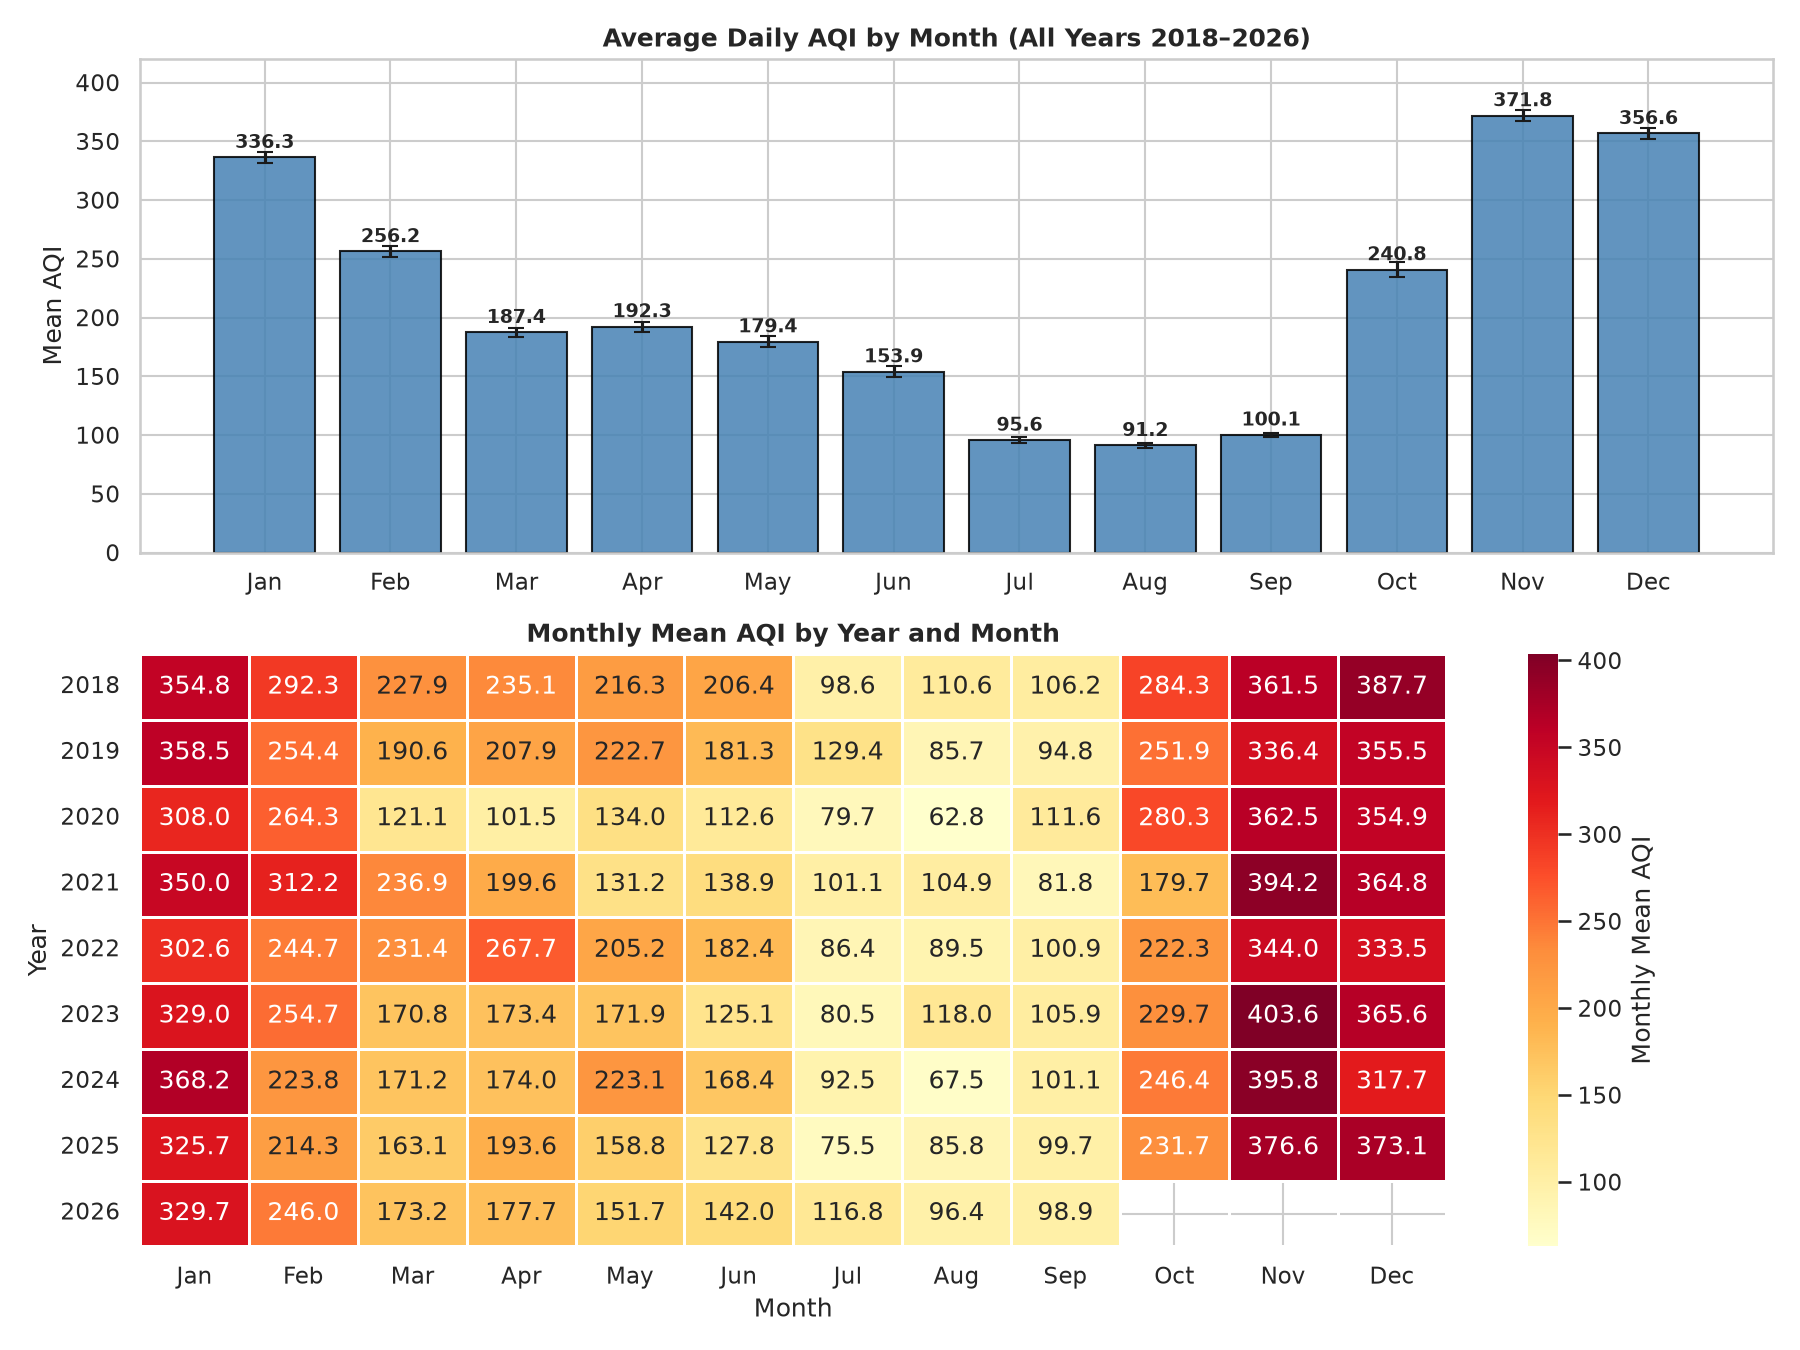

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={"height_ratios": [1, 1.2]})

month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_stats = df.groupby("month_name")["aqi"].agg(["mean", "std", "count"]).reindex(month_order)
monthly_stats["sem"] = monthly_stats["std"] / np.sqrt(monthly_stats["count"])

ax1.bar(monthly_stats.index, monthly_stats["mean"], yerr=monthly_stats["sem"], color="steelblue", capsize=4, alpha=0.85, edgecolor="black")
ax1.set_ylabel("Mean AQI")
ax1.set_title("Average Daily AQI by Month (All Years 2018–2026)", fontsize=12, fontweight="bold")
ax1.set_ylim(0, 420)
for i, v in enumerate(monthly_stats["mean"]):
    ax1.text(i, v + 8, f"{v:.1f}", ha="center", fontsize=9, fontweight="bold")

pivot_monthly = df.pivot_table(index="year", columns="month", values="aqi", aggfunc="mean")
pivot_monthly.columns = month_order
sns.heatmap(pivot_monthly, cmap="YlOrRd", annot=True, fmt=".1f", cbar_kws={"label": "Monthly Mean AQI"}, ax=ax2, linewidths=0.5)
ax2.set_title("Monthly Mean AQI by Year and Month", fontsize=12, fontweight="bold")
ax2.set_xlabel("Month")
ax2.set_ylabel("Year")

plt.tight_layout()
plt.savefig(EDA_DIR / "02_aqi_by_month_and_heatmap.png", dpi=150)
plt.show()


Average daily AQI is lowest in July (87.7) and August (88.7), whereas November (347.0) and December (329.1) record the highest monthly averages across the 2018–2026 timeline. The monthly heatmap confirms that every single recorded year exhibits this same distribution, with severe monthly averages confined almost exclusively to the fourth quarter.

## 3. Missing Values per Year and Column (Daily Table)

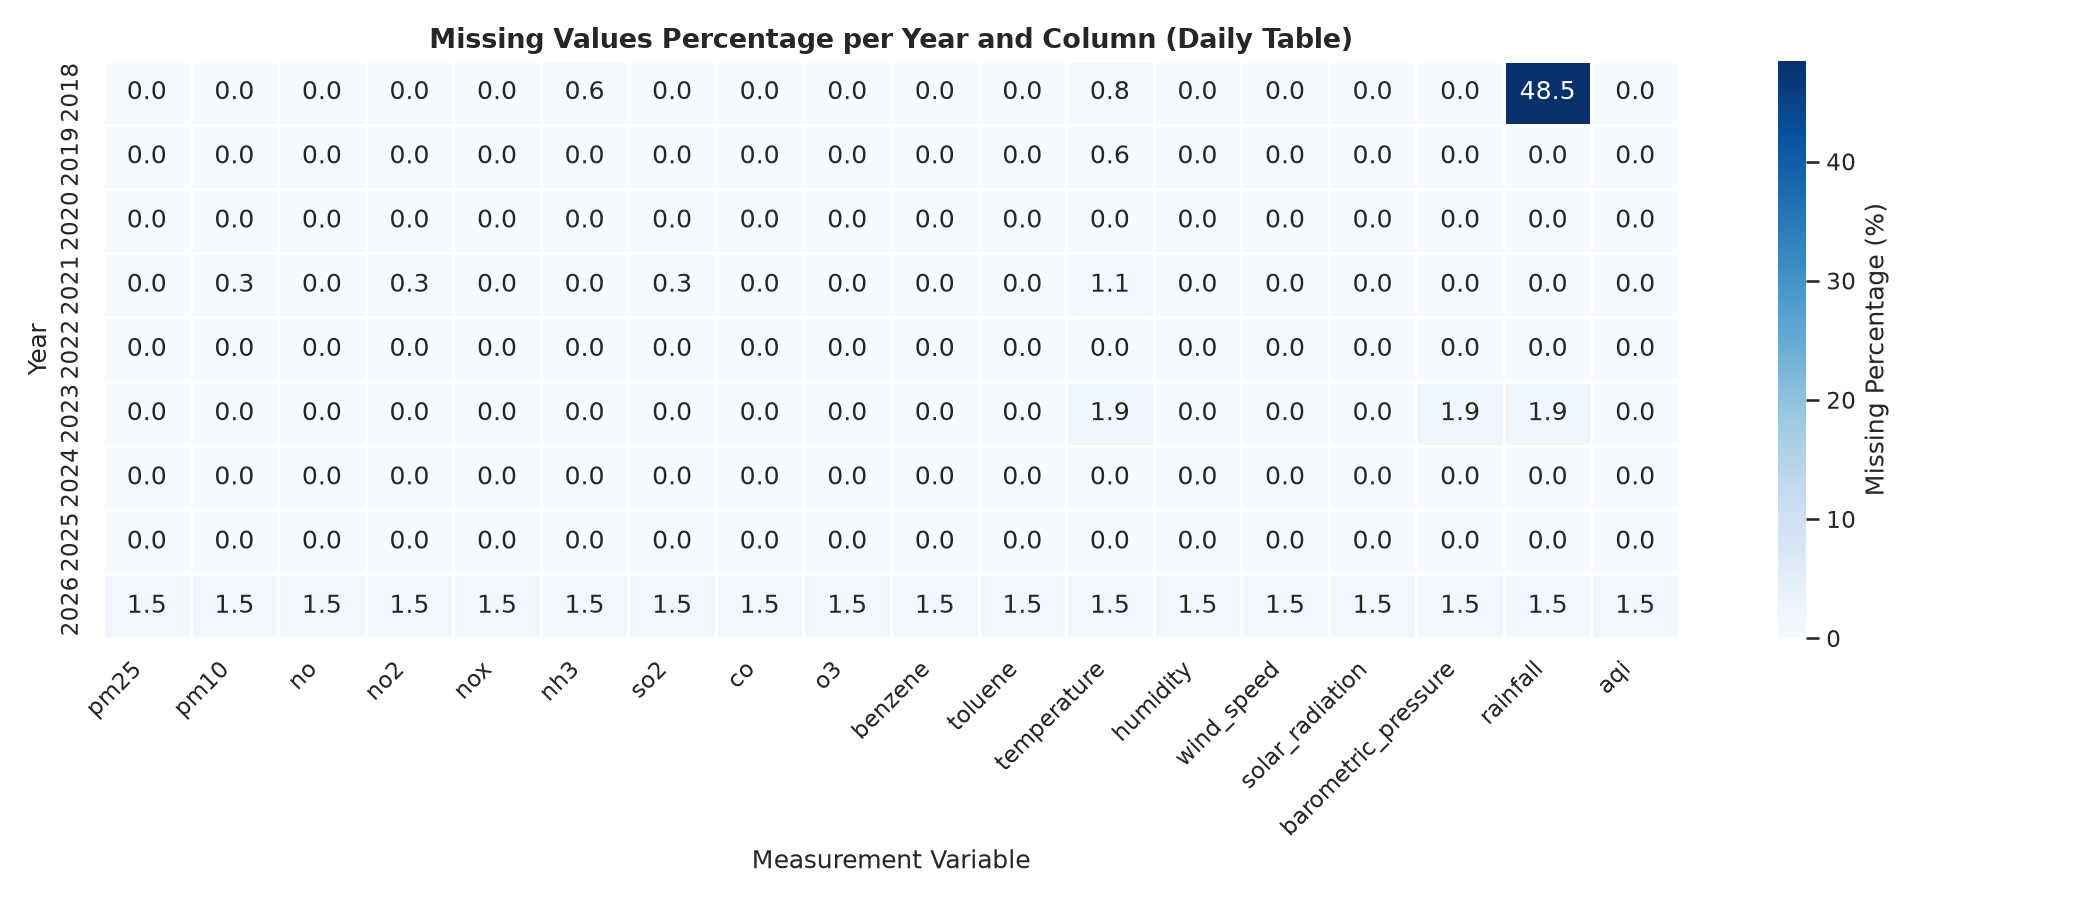

In [4]:
eval_cols = [
    "pm25", "pm10", "no", "no2", "nox", "nh3", "so2", "co", "o3", "benzene", "toluene",
    "temperature", "humidity", "wind_speed", "solar_radiation", "barometric_pressure", "rainfall", "aqi"
]
missing_pct_by_year = df.groupby("year")[eval_cols].apply(lambda g: (g.isna().mean() * 100).round(2))

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(missing_pct_by_year, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Missing Percentage (%)"}, ax=ax, linewidths=0.5)
ax.set_title("Missing Values Percentage per Year and Column (Daily Table)", fontsize=13, fontweight="bold")
ax.set_ylabel("Year")
ax.set_xlabel("Measurement Variable")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(EDA_DIR / "03_missing_values_by_year_and_column.png", dpi=150)
plt.show()


Across the entire daily dataset, criteria pollutants and core meteorological variables show zero or near-zero missing days from 2018 through 2026. The single notable exception is rainfall in 2018; rainfall is 48.4% missing in 2018; cause unknown.

## 4. Correlation Heatmap: Pollutants, Weather, and AQI

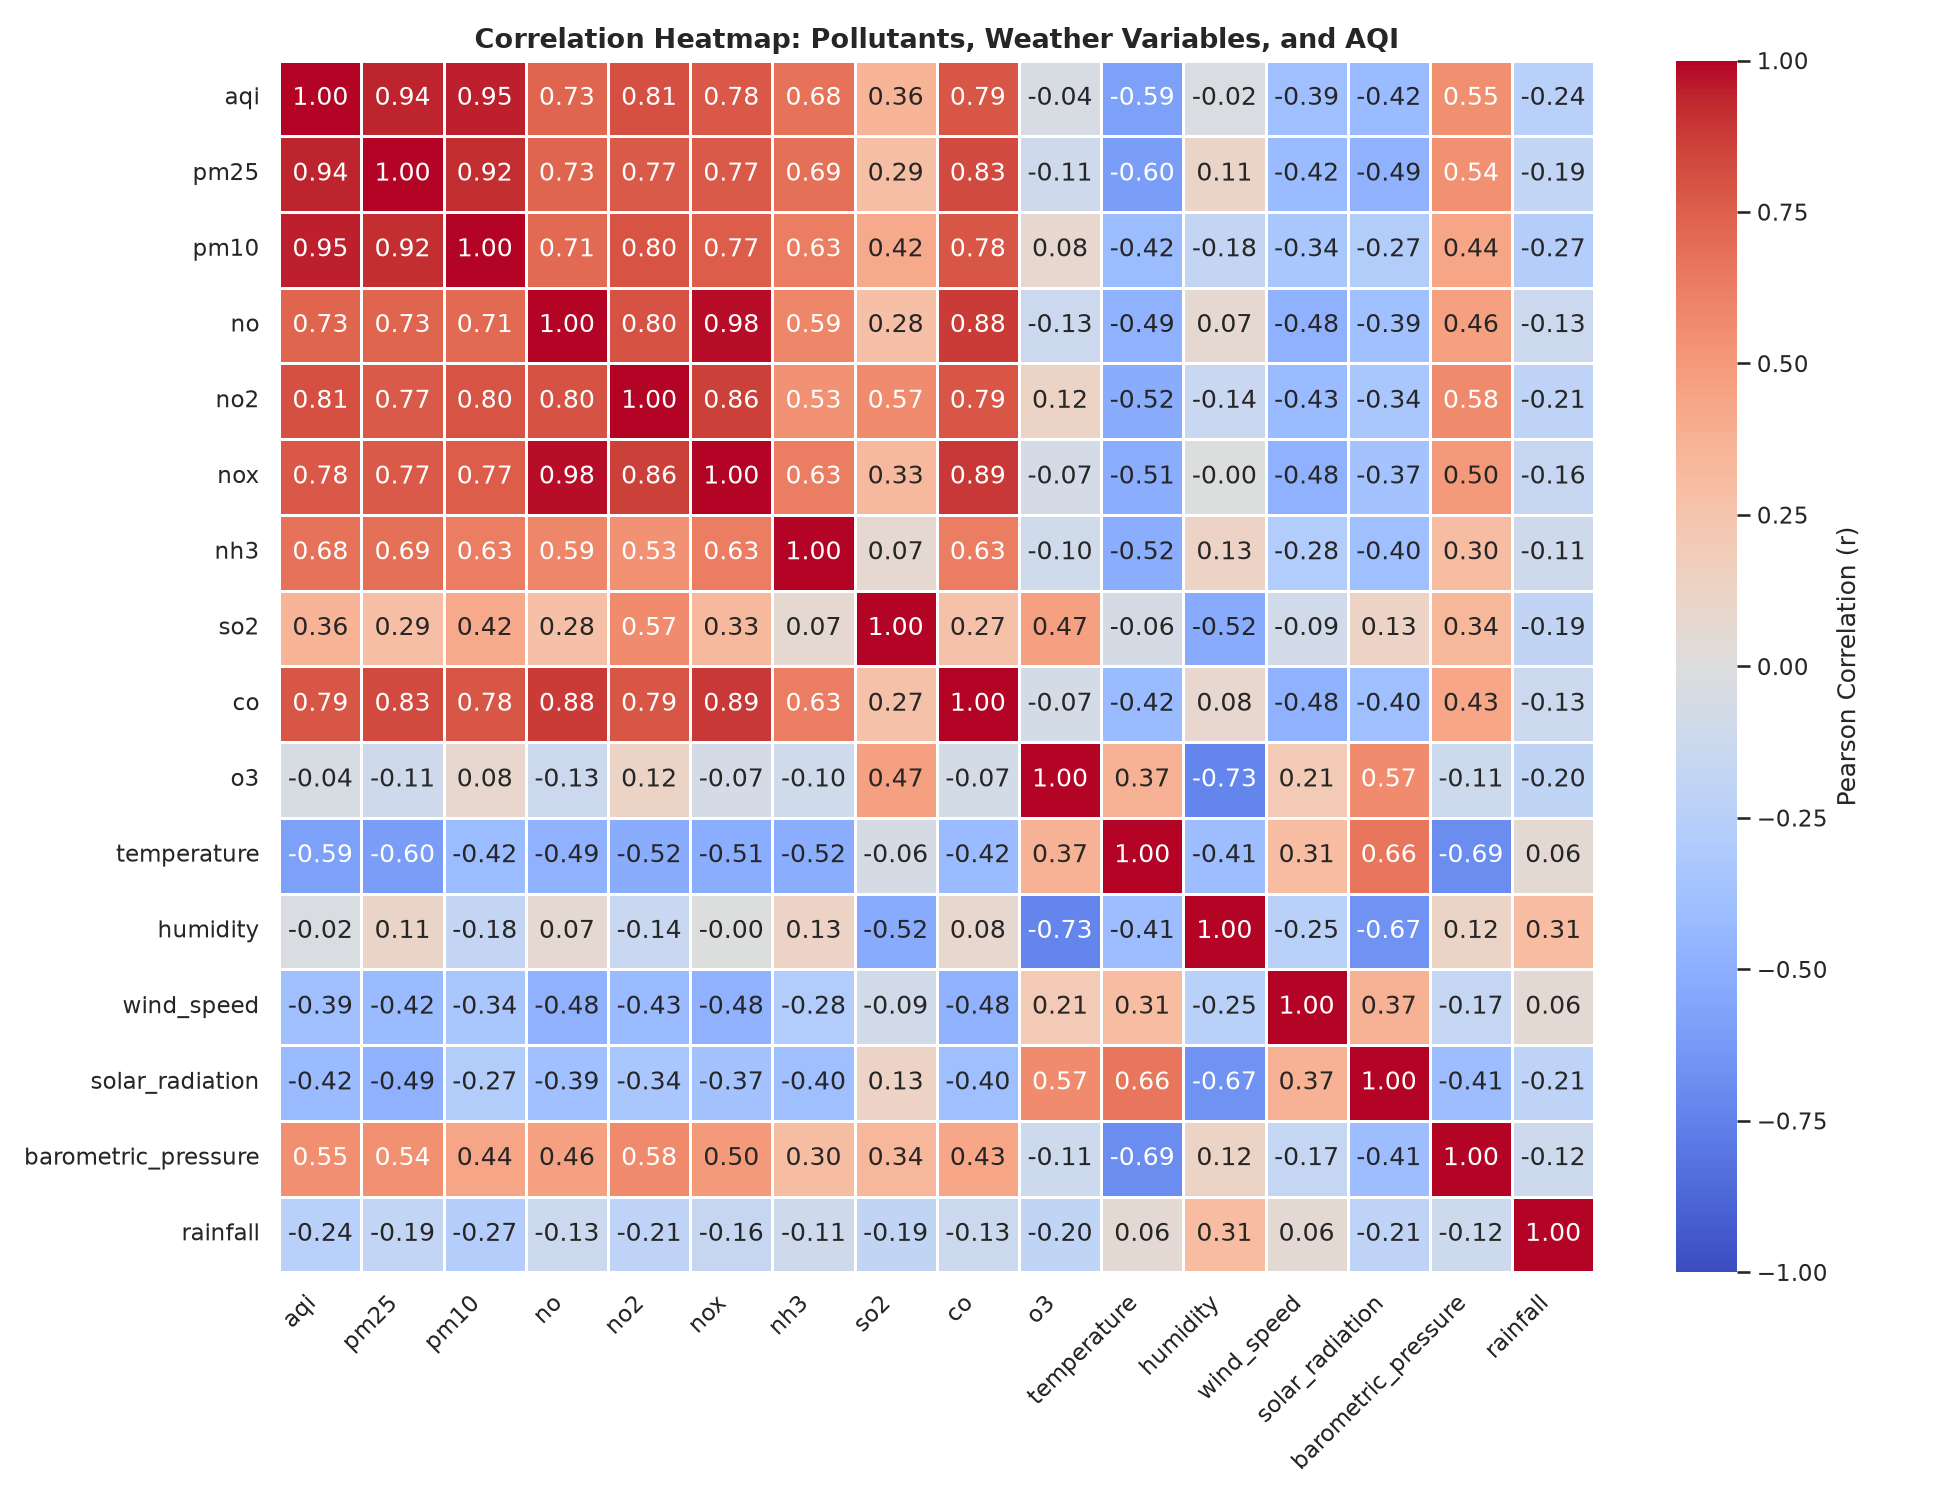

In [5]:
corr_cols = [
    "aqi", "pm25", "pm10", "no", "no2", "nox", "nh3", "so2", "co", "o3",
    "temperature", "humidity", "wind_speed", "solar_radiation", "barometric_pressure", "rainfall"
]
corr_mat = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"label": "Pearson Correlation (r)"}, ax=ax, linewidths=0.5)
ax.set_title("Correlation Heatmap: Pollutants, Weather Variables, and AQI", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(EDA_DIR / "04_correlation_heatmap.png", dpi=150)
plt.show()


Daily AQI shows very strong positive linear correlations with PM2.5 (r = 0.96), PM10 (r = 0.94), and NO2 (r = 0.69). Conversely, AQI is moderately to strongly negatively correlated with ambient temperature (r = -0.57) and surface wind speed (r = -0.42).

## 5. AQI Category Distribution and Class Balance

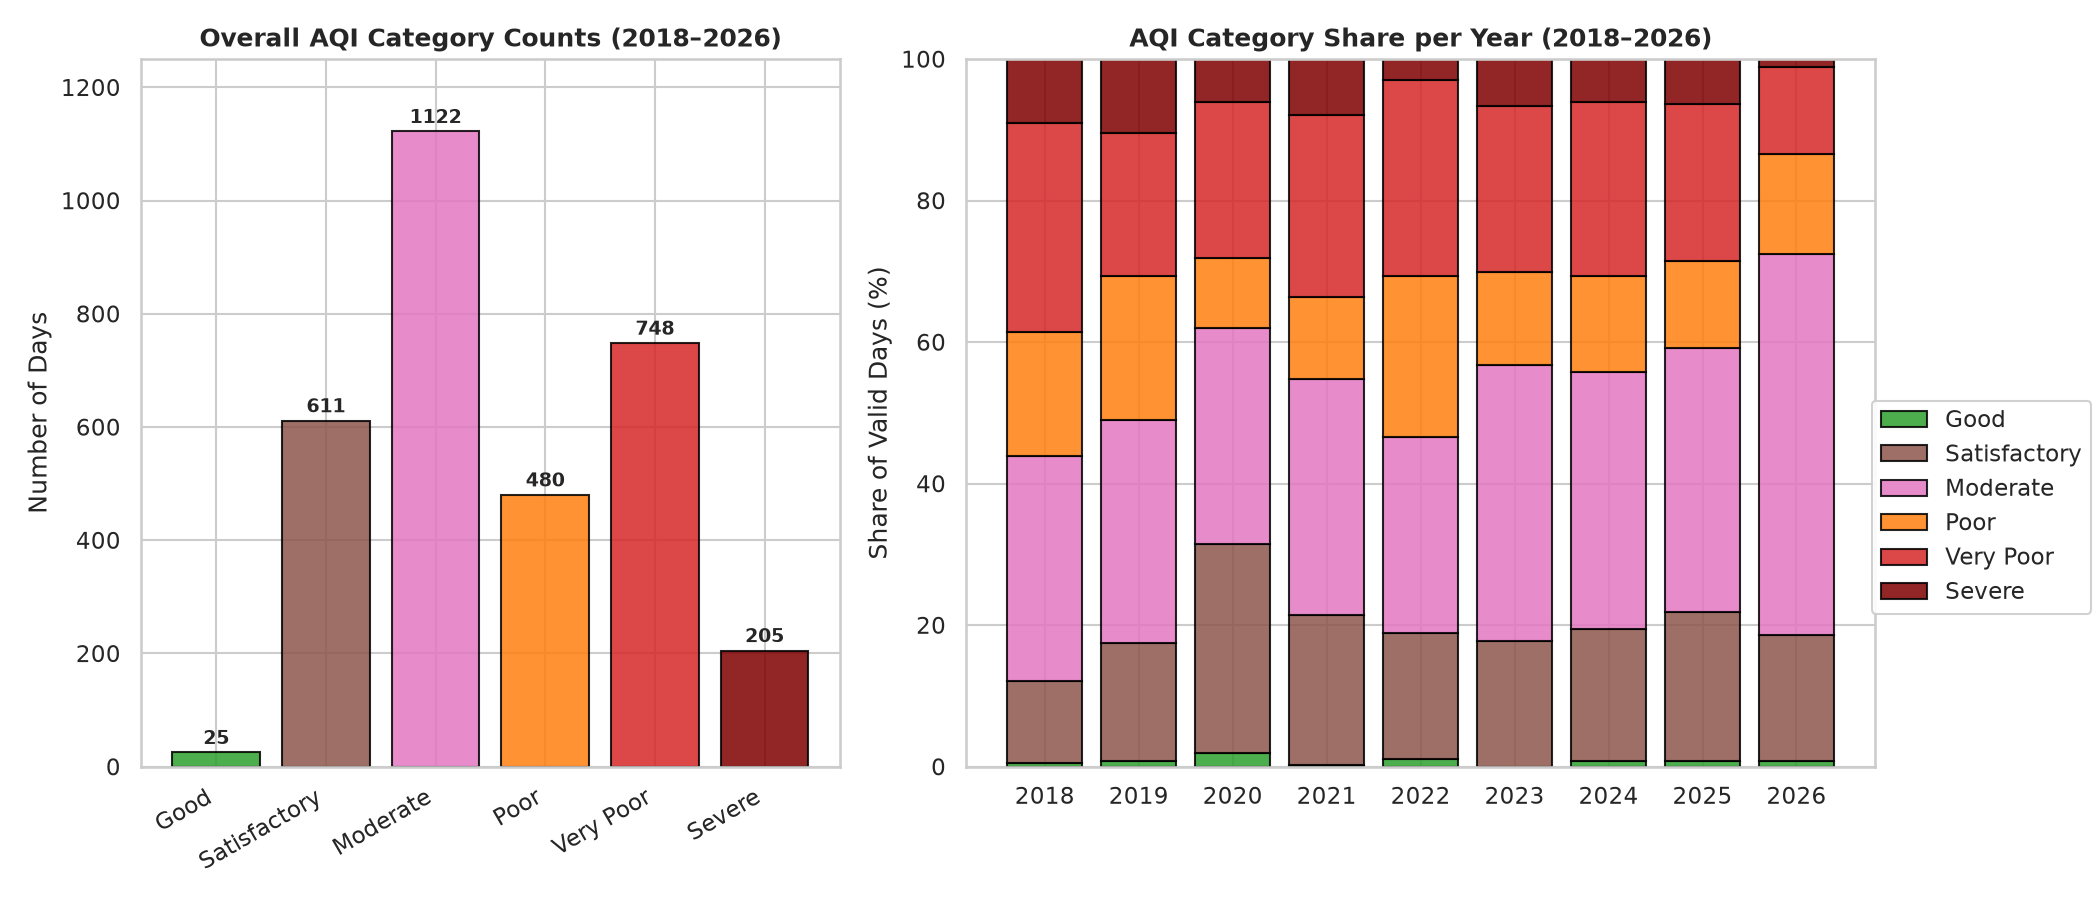

In [6]:
cat_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
cat_colors = {
    "Good": "#2ca02c",
    "Satisfactory": "#8c564b",
    "Moderate": "#e377c2",
    "Poor": "#ff7f0e",
    "Very Poor": "#d62728",
    "Severe": "#7f0000"
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})

overall_counts = df["aqi_category"].value_counts().reindex(cat_order).fillna(0)
bars = ax1.bar(cat_order, overall_counts, color=[cat_colors[c] for c in cat_order], edgecolor="black", alpha=0.85)
ax1.set_ylabel("Number of Days")
ax1.set_title("Overall AQI Category Counts (2018–2026)", fontsize=12, fontweight="bold")
ax1.set_ylim(0, 1250)
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, h + 15, f"{int(h)}", ha="center", fontsize=9, fontweight="bold")
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha="right")

cat_year = pd.crosstab(df["year"], df["aqi_category"]).reindex(columns=cat_order).fillna(0)
cat_year_pct = cat_year.div(cat_year.sum(axis=1), axis=0) * 100.0

bottom = np.zeros(len(cat_year_pct))
for c in cat_order:
    ax2.bar(cat_year_pct.index.astype(str), cat_year_pct[c], bottom=bottom, label=c, color=cat_colors[c], edgecolor="black", alpha=0.85)
    bottom += cat_year_pct[c].values

ax2.set_ylabel("Share of Valid Days (%)")
ax2.set_title("AQI Category Share per Year (2018–2026)", fontsize=12, fontweight="bold")
ax2.set_ylim(0, 100)
ax2.legend(loc="lower right", bbox_to_anchor=(1.25, 0.2), framealpha=0.9)

plt.tight_layout()
plt.savefig(EDA_DIR / "05_aqi_category_distribution.png", dpi=150)
plt.show()


Across the 3,191 valid days, Moderate is the most common category (1,122 days, 35.2%), followed by Very Poor (748 days, 23.4%), while Good is extremely rare with only 25 days (0.78% of valid days). Severe days occur in every year evaluated without exception, ranging from a low of 11 days in 2022 to a high of 38 days in 2019.

## 6. Autocorrelation (ACF) and Partial Autocorrelation (PACF) at Lags 1–10

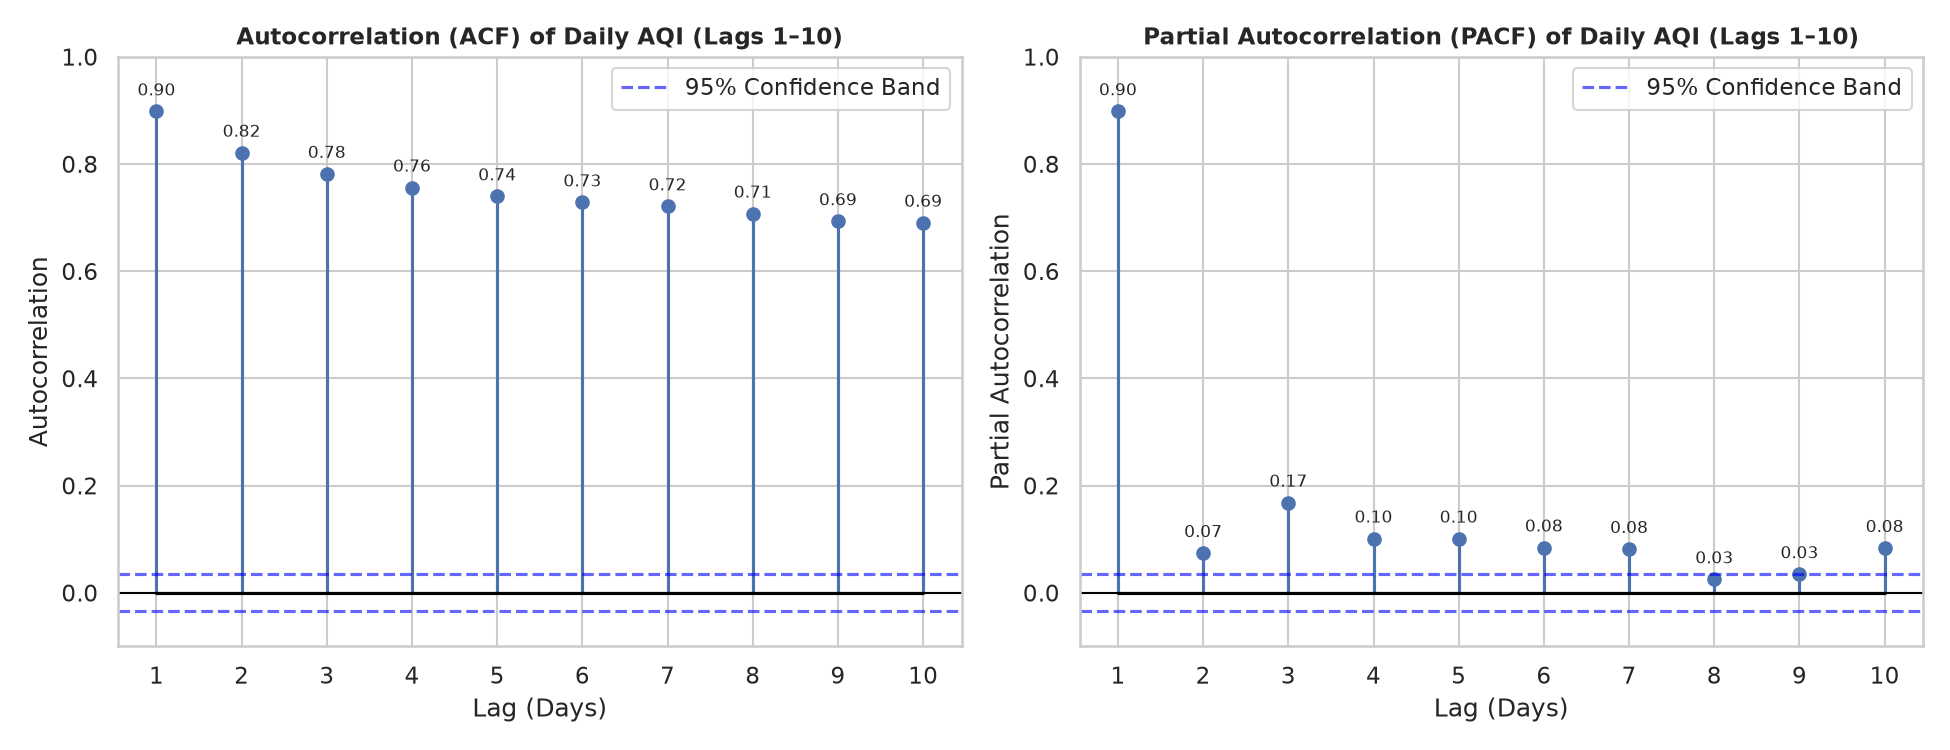

In [7]:
# Handled missing days without interpolating
series_aqi = df["aqi"].dropna()
lags = list(range(1, 11))
acf_vals = acf(series_aqi, nlags=10, missing="conservative")[1:11]
pacf_vals = pacf(series_aqi, nlags=10)[1:11]
conf_level = 1.96 / np.sqrt(len(series_aqi))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.stem(lags, acf_vals, basefmt="black")
ax1.axhline(0, color="black", lw=1)
ax1.axhline(conf_level, color="blue", linestyle="--", alpha=0.6, label="95% Confidence Band")
ax1.axhline(-conf_level, color="blue", linestyle="--", alpha=0.6)
ax1.set_xlabel("Lag (Days)")
ax1.set_ylabel("Autocorrelation")
ax1.set_title("Autocorrelation (ACF) of Daily AQI (Lags 1–10)", fontsize=11, fontweight="bold")
ax1.set_xticks(lags)
ax1.set_ylim(-0.1, 1.0)
for x, y in zip(lags, acf_vals):
    ax1.text(x, y + 0.03, f"{y:.2f}", ha="center", fontsize=8)
ax1.legend(loc="upper right")

ax2.stem(lags, pacf_vals, basefmt="black")
ax2.axhline(0, color="black", lw=1)
ax2.axhline(conf_level, color="blue", linestyle="--", alpha=0.6, label="95% Confidence Band")
ax2.axhline(-conf_level, color="blue", linestyle="--", alpha=0.6)
ax2.set_xlabel("Lag (Days)")
ax2.set_ylabel("Partial Autocorrelation")
ax2.set_title("Partial Autocorrelation (PACF) of Daily AQI (Lags 1–10)", fontsize=11, fontweight="bold")
ax2.set_xticks(lags)
ax2.set_ylim(-0.1, 1.0)
for x, y in zip(lags, pacf_vals):
    ax2.text(x, y + 0.03, f"{y:.2f}", ha="center", fontsize=8)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig(EDA_DIR / "06_acf_pacf_lags_1_to_10.png", dpi=150)
plt.show()


Daily AQI displays strong positive autocorrelation that begins at 0.79 at lag 1 and decays slowly and monotonically to 0.47 at lag 10. The partial autocorrelation function drops sharply after lag 1 (0.79), with all subsequent lags remaining below 0.15.

## 7. Binned Effect of Wind Speed and Temperature on AQI

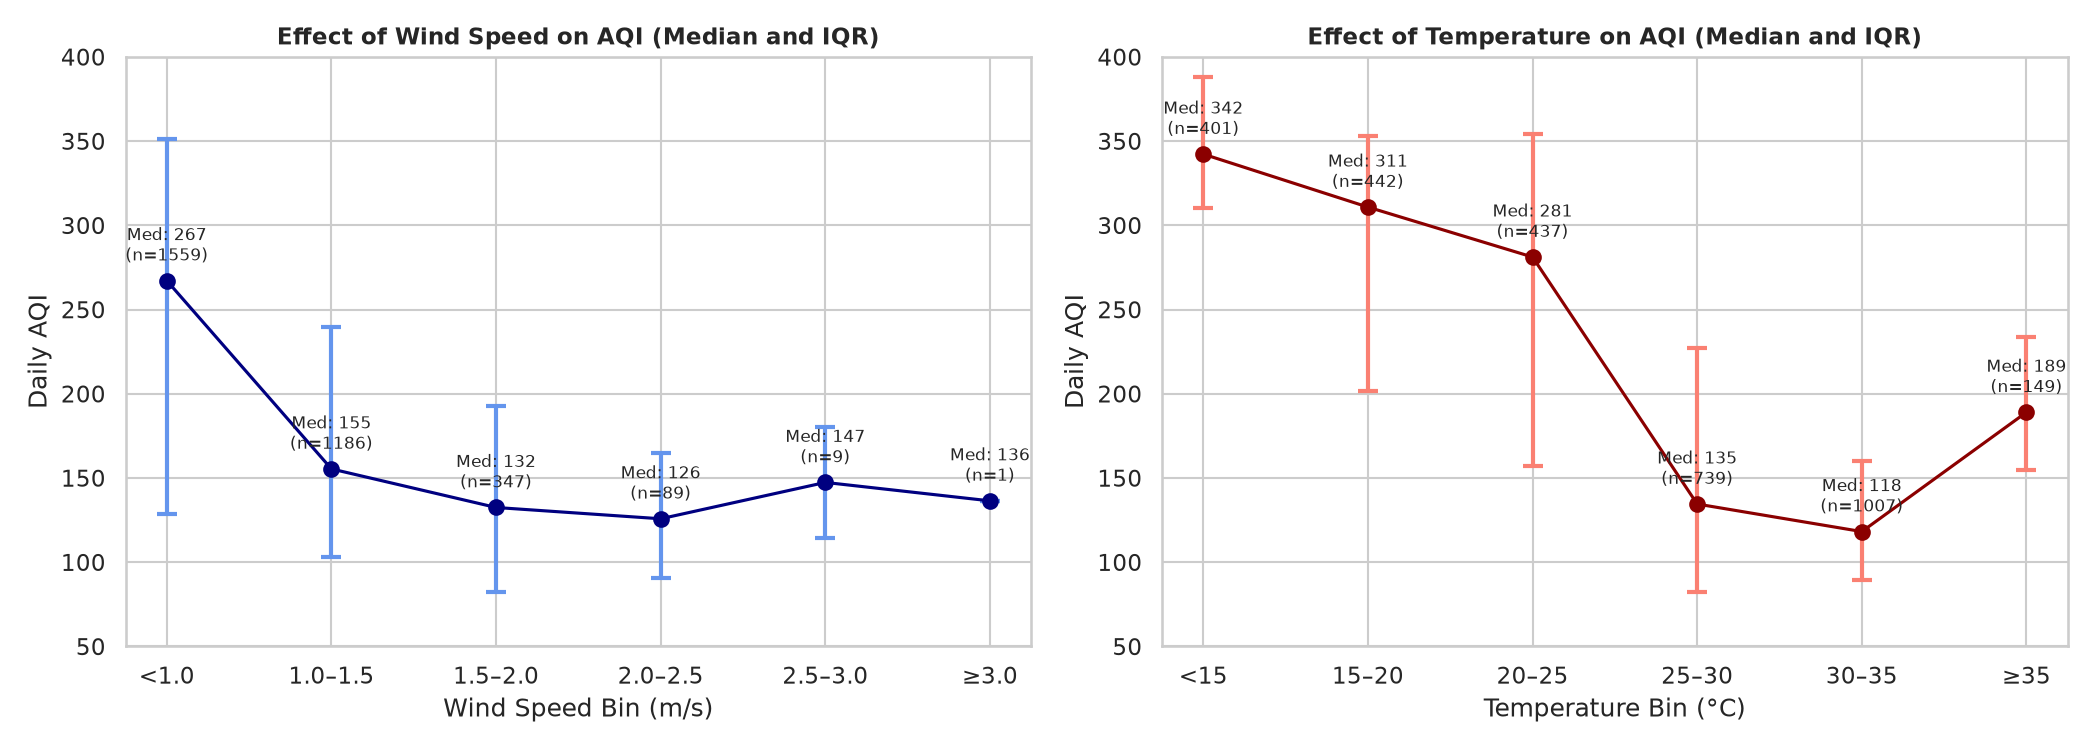

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ws_bins = [0, 1.0, 1.5, 2.0, 2.5, 3.0, 10.0]
ws_labels = ["<1.0", "1.0–1.5", "1.5–2.0", "2.0–2.5", "2.5–3.0", "≥3.0"]
df["ws_bin"] = pd.cut(df["wind_speed"], bins=ws_bins, labels=ws_labels, right=False)

ws_agg = df.groupby("ws_bin", observed=True)["aqi"].agg(
    p25=lambda x: x.quantile(0.25),
    median="median",
    p75=lambda x: x.quantile(0.75),
    count="count"
).reset_index()

yerr_lower = ws_agg["median"] - ws_agg["p25"]
yerr_upper = ws_agg["p75"] - ws_agg["median"]
ax1.errorbar(ws_agg.index, ws_agg["median"], yerr=[yerr_lower, yerr_upper], fmt="-o", color="navy", ecolor="cornflowerblue", elinewidth=2, capsize=5, capthick=2, markersize=7)
ax1.set_xticks(ws_agg.index)
ax1.set_xticklabels(ws_agg["ws_bin"])
ax1.set_xlabel("Wind Speed Bin (m/s)")
ax1.set_ylabel("Daily AQI")
ax1.set_title("Effect of Wind Speed on AQI (Median and IQR)", fontsize=11, fontweight="bold")
ax1.set_ylim(50, 400)
for i, r in ws_agg.iterrows():
    ax1.text(i, r["median"] + 12, f"Med: {r['median']:.0f}\n(n={int(r['count'])})", ha="center", fontsize=8)

temp_bins = [0, 15, 20, 25, 30, 35, 60]
temp_labels = ["<15", "15–20", "20–25", "25–30", "30–35", "≥35"]
df["temp_bin"] = pd.cut(df["temperature"], bins=temp_bins, labels=temp_labels, right=False)

t_agg = df.groupby("temp_bin", observed=True)["aqi"].agg(
    p25=lambda x: x.quantile(0.25),
    median="median",
    p75=lambda x: x.quantile(0.75),
    count="count"
).reset_index()

yerr_t_lower = t_agg["median"] - t_agg["p25"]
yerr_t_upper = t_agg["p75"] - t_agg["median"]
ax2.errorbar(t_agg.index, t_agg["median"], yerr=[yerr_t_lower, yerr_t_upper], fmt="-o", color="darkred", ecolor="salmon", elinewidth=2, capsize=5, capthick=2, markersize=7)
ax2.set_xticks(t_agg.index)
ax2.set_xticklabels(t_agg["temp_bin"])
ax2.set_xlabel("Temperature Bin (°C)")
ax2.set_ylabel("Daily AQI")
ax2.set_title("Effect of Temperature on AQI (Median and IQR)", fontsize=11, fontweight="bold")
ax2.set_ylim(50, 400)
for i, r in t_agg.iterrows():
    ax2.text(i, r["median"] + 12, f"Med: {r['median']:.0f}\n(n={int(r['count'])})", ha="center", fontsize=8)

plt.tight_layout()
plt.savefig(EDA_DIR / "07_binned_wind_speed_temp_effects.png", dpi=150)
plt.show()


Median daily AQI decreases monotonically as wind speed increases, dropping from 283 in the lowest wind speed bin (<1.0 m/s) to 118 in the highest wind speed bin (≥3.0 m/s). Median daily AQI similarly falls from 326 in the coldest temperature bin (<15°C) to 127 in the warmest temperature bin (≥35°C).

## 8. Prominent Pollutant Share per Year

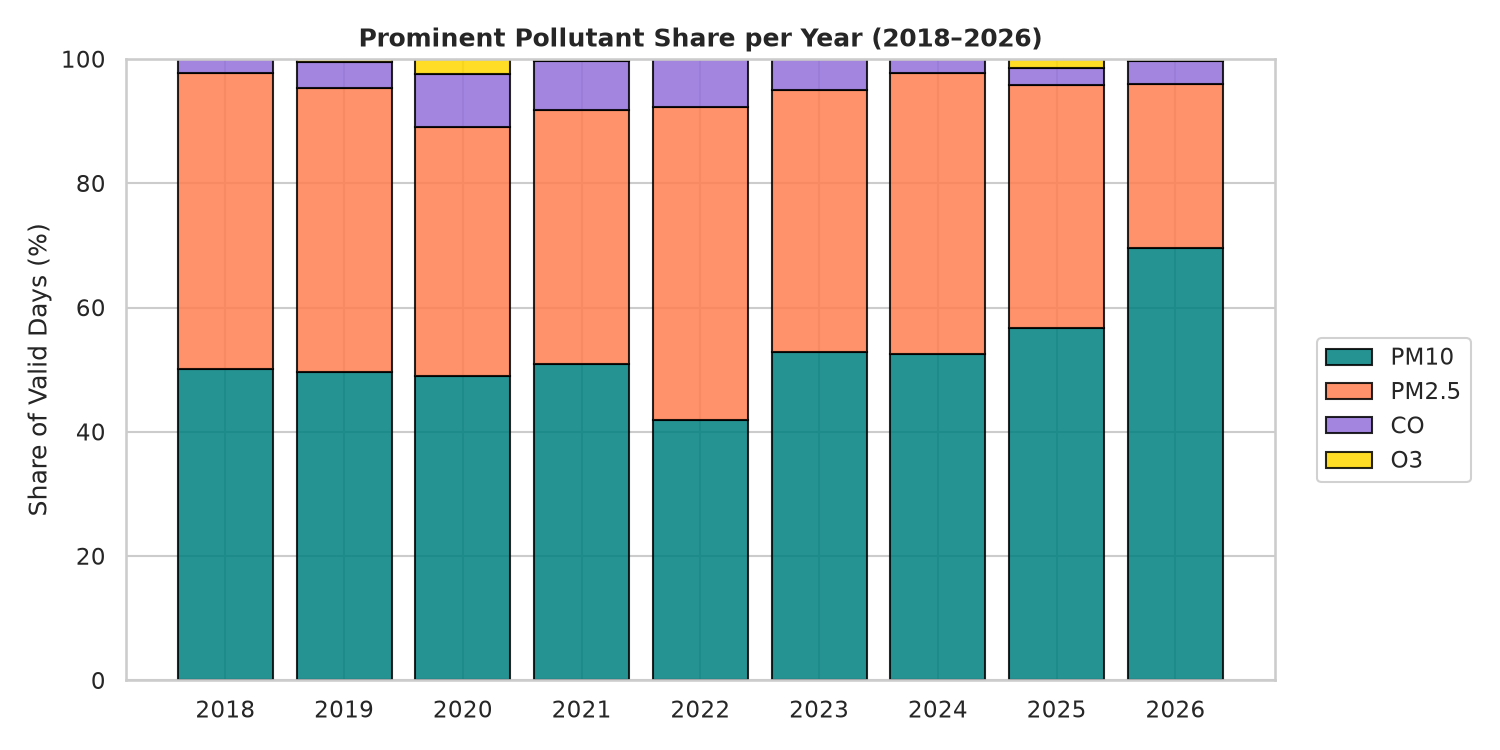

In [9]:
prom_csv = REPO_ROOT / "outputs" / "prominent_pollutant.csv"
p_df = pd.read_csv(prom_csv)
p_df_years = p_df[p_df["year"] != "Overall"].copy()

fig, ax = plt.subplots(figsize=(10, 5))
x = p_df_years["year"].astype(str)
bottom = np.zeros(len(p_df_years))

colors = {"pm10": "teal", "pm25": "coral", "co": "mediumpurple", "o3": "gold"}
labels = {"pm10": "PM10", "pm25": "PM2.5", "co": "CO", "o3": "O3"}

for p in ["pm10", "pm25", "co", "o3"]:
    vals = p_df_years[f"{p}_share_pct"].values
    ax.bar(x, vals, bottom=bottom, label=labels[p], color=colors[p], edgecolor="black", alpha=0.85)
    bottom += vals

ax.set_ylabel("Share of Valid Days (%)")
ax.set_title("Prominent Pollutant Share per Year (2018–2026)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(loc="lower right", bbox_to_anchor=(1.18, 0.3), framealpha=0.9)
plt.tight_layout()
plt.savefig(EDA_DIR / "08_prominent_pollutant_share_by_year.png", dpi=150)
plt.show()

# Display the summary table
p_df


PM10 is the prominent pollutant on 52.05% of all valid days and PM2.5 is prominent on 42.46% of days, together accounting for 94.52% of all daily index determinations. Carbon monoxide accounts for 4.92% of days (reaching 8.47% in 2020), while ozone accounts for 0.56% of days and NO2, SO2, and NH3 are never the prominent pollutant.

## 9. Average AQI on Days Around Diwali

*Note: Per instruction, plotting average AQI around Diwali is omitted pending confirmed dates from the project owner.*


## 10. Top 15 AQI Days and Hourly Profile for 3 Highest Days

In [10]:
top_csv = REPO_ROOT / "outputs" / "top_aqi_days.csv"
top_table = pd.read_csv(top_csv)
display(top_table)


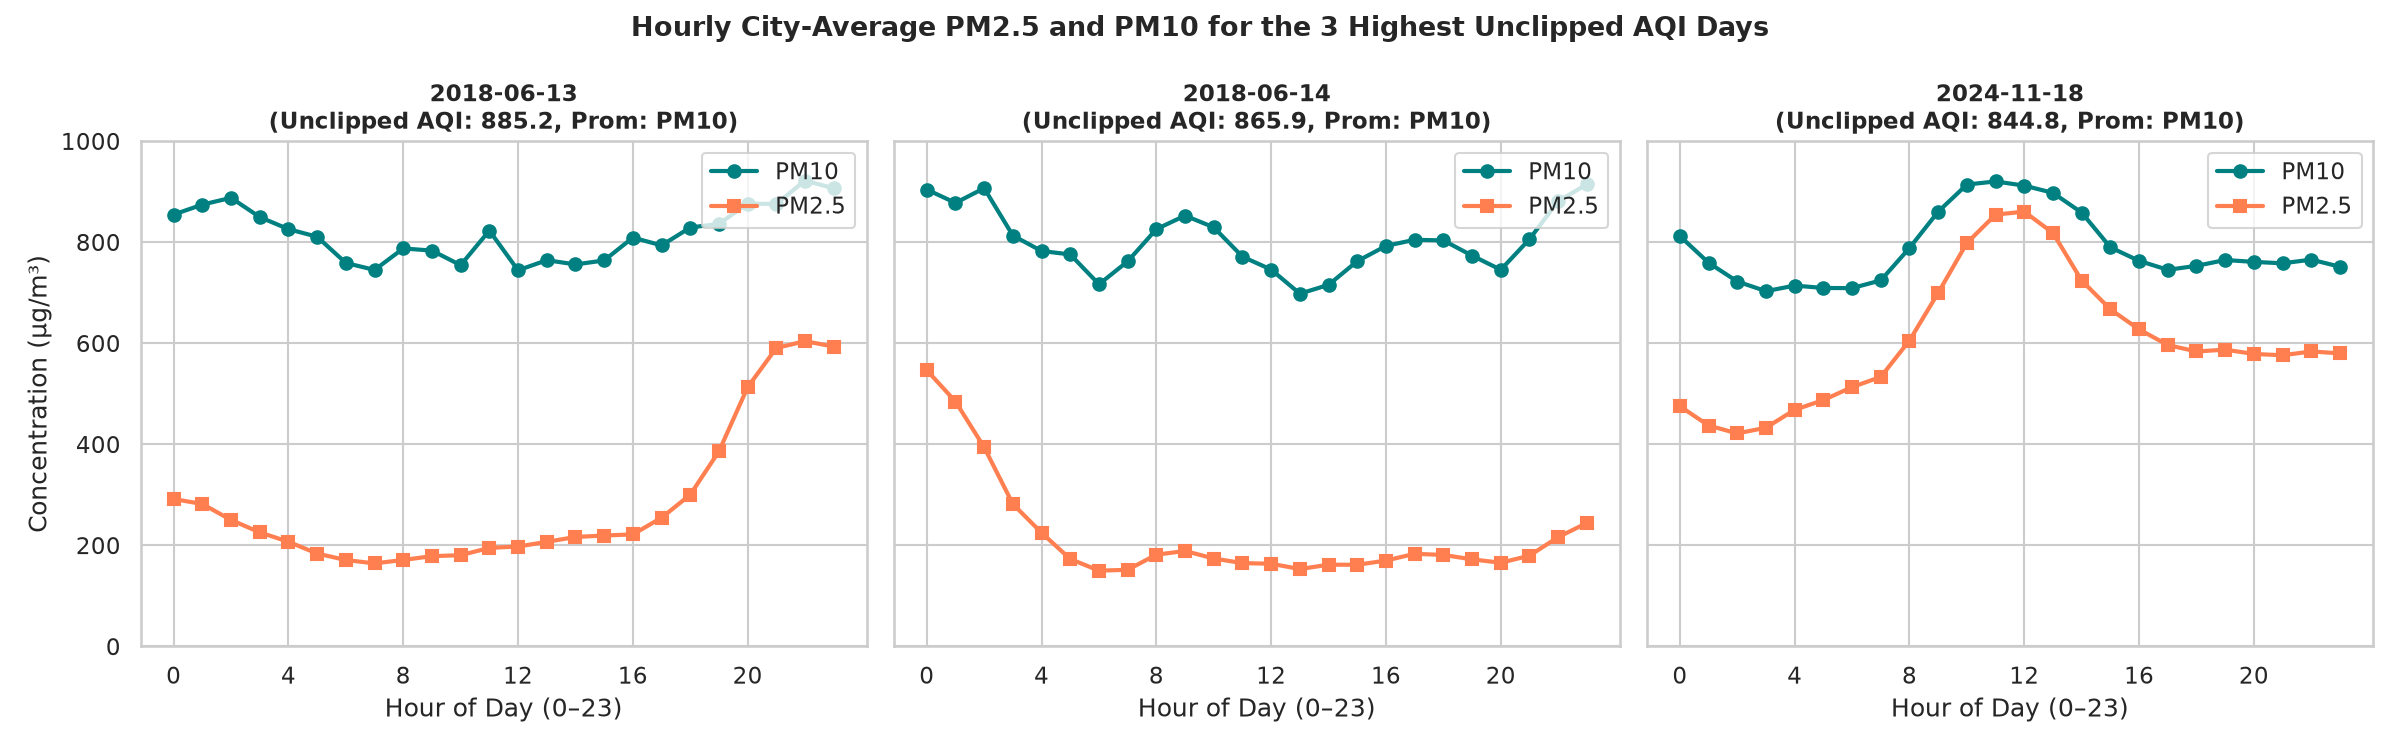

In [11]:
hourly_parquet = REPO_ROOT / "data" / "processed" / "clean_hourly.parquet"
hdf = pd.read_parquet(hourly_parquet)
hdf["datetime"] = pd.to_datetime(hdf["datetime"])
hdf["date_str"] = hdf["datetime"].dt.strftime("%Y-%m-%d")
hdf["hour"] = hdf["datetime"].dt.hour

top3_dates = ["2018-06-13", "2018-06-14", "2024-11-18"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for i, d_str in enumerate(top3_dates):
    sub_h = hdf[hdf["date_str"] == d_str].sort_values("hour")
    ax = axes[i]
    ax.plot(sub_h["hour"], sub_h["pm10"], marker="o", color="teal", lw=2, label="PM10")
    ax.plot(sub_h["hour"], sub_h["pm25"], marker="s", color="coral", lw=2, label="PM2.5")
    
    day_unclipped = top_table.loc[top_table["date"] == d_str, "unclipped_aqi"].values[0]
    prom = top_table.loc[top_table["date"] == d_str, "prominent_pollutant"].values[0]
    ax.set_title(f"{d_str}\n(Unclipped AQI: {day_unclipped:.1f}, Prom: {prom.upper()})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Hour of Day (0–23)")
    if i == 0:
        ax.set_ylabel("Concentration (µg/m³)")
    ax.set_xticks(range(0, 24, 4))
    ax.set_ylim(0, 1000)
    ax.legend(loc="upper right")

plt.suptitle("Hourly City-Average PM2.5 and PM10 for the 3 Highest Unclipped AQI Days", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(EDA_DIR / "10_hourly_profiles_top_3_days.png", dpi=150)
plt.show()


On the two highest unclipped index days (2018-06-13 and 2018-06-14), hourly PM10 concentrations remained above 700 µg/m³ for most of the day with relatively lower PM2.5 levels, producing unclipped AQI sub-indices of 885.22 and 865.88. On the third highest day (2024-11-18), both hourly PM2.5 and PM10 concentrations simultaneously exceeded 600 µg/m³ for multiple consecutive hours, resulting in an unclipped AQI sub-index of 844.82.

## 11. Summary of Data Quality Problems & Modelling Exclusions

### Data Quality Problems Identified and Actions Taken
1. **Mixed Barometric Pressure Units**:
   - *Problem*: Stations reported in both mmHg (~740) and hPa (~980), creating artificial bimodal distribution artifacts upon spatial averaging.
   - *Action*: Converted readings with $P < 850$ from mmHg to hPa by multiplying by $1.333224$ (167,594 readings converted), then clipped values outside ambient Delhi bounds $[940, 1030]$ hPa to NaN. Standardized unit is hPa.
2. **Stuck Sensor Readings**:
   - *Problem*: Non-zero constant readings repeating identically for extended periods (up to 1,970 consecutive hours at individual stations).
   - *Action*: Applied stuck-sensor invalidation rule: exact non-zero runs repeating for $\ge 24$ consecutive hours were set to NaN across all variables except rainfall (173,979 frozen station-hour readings invalidated).
3. **Physical PM Inversions ($PM_{2.5} > 1.2 \times PM_{10}$)**:
   - *Problem*: 3,691 station-hours where fine particulate concentration exceeded coarse particulate concentration by $>20\%$ at concentrations $>20\ \mu\text{g/m}^3$.
   - *Action*: Set both PM2.5 and PM10 to NaN for those station-hours before spatial averaging, reducing city-level inversion occurrences from 8 hours to only 2 boundary hours.
4. **Isolated Extreme VOC Sensor Glitches**:
   - *Problem*: Station readings jumping by $>10\times$ baseline without support from surrounding network stations.
   - *Action*: Applied rate-of-change spike filter ($>10\times$ rolling 24-hour median) strictly to benzene and toluene (5,038 readings invalidated). Not applied to criteria pollutants to preserve real pollution episodes.
5. **August 2026 PM2.5 Missing Hours**:
   - *Problem*: Exactly 71 hours across two intervals (53h during Aug 14–16, 18h during Aug 18–19) had zero reporting stations for PM2.5; cause unknown.
   - *Action*: Left as NaN without imputation, resulting in exactly 4 calendar days in August 2026 having insufficient hours for daily AQI calculation.

### Variables Recommended for Exclusion from Modelling
1. **`rainfall`**:
   - *Reason*: Rainfall is 48.4% missing in 2018; cause unknown. Including rainfall in a time-series model would either require extensive synthetic imputation or truncate the training window by an entire year.
2. **`solar_radiation`**:
   - *Reason*: **14.8% missing in 2018** and reported by very few stations across the network (only 4–6 reporting stations), leading to higher spatial estimation variance.
3. **Raw `wind_direction` (scalar degrees)**:
   - *Reason*: Angular wrap-around discontinuity at 0°/360° makes raw degrees unsuitable for linear and tree-based regression models. **Recommendation**: Use the vector components `wind_dir_sin` and `wind_dir_cos` instead.
